In [10]:
import re
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from pyproj import CRS

# Load aggregated table
df = pd.read_csv("mars_age_tiles_agg_run2.csv")

# 1) Get exact centroids (no rounding)
pat_src = re.compile(r"lat(?P<lat>[-+0-9.]+)_lon(?P<lon>[-+0-9.]+)\.scc$", re.I)

def pick_lat_lon(row):
    # Prefer exact columns if they exist
    if "centroid_lat_exact" in row and "centroid_lon_exact" in row:
        return float(row["centroid_lat_exact"]), float(row["centroid_lon_exact"])
    # Next: parse from Source path
    m = pat_src.search(str(row.get("Source", "")))
    if m:
        return float(m.group("lat")), float(m.group("lon"))
    # Fallback: existing centroid columns
    return float(row["centroid_lat"]), float(row["centroid_lon"])

lats, lons = zip(*df.apply(pick_lat_lon, axis=1))
df["centroid_lat"] = lats
df["centroid_lon"] = lons

# (Optional) wrap to -180..180 instead of 0–360
# df["centroid_lon"] = ((df["centroid_lon"] + 180) % 360) - 180

# 2) Build geometry from exact lon/lat
geometry = [Point(xy) for xy in zip(df["centroid_lon"], df["centroid_lat"])]
gdf = gpd.GeoDataFrame(df.copy(), geometry=geometry)

# 3) Set Mars geographic CRS (planetocentric long/lat on Mars 2000 ellipsoid)
mars_geog = CRS.from_proj4("+proj=longlat +a=3396190 +b=3376200 +no_defs +type=crs")
gdf = gdf.set_crs(mars_geog, allow_override=True)

# 4) Save
gdf.to_file("mars_age_tiles_points.gpkg", layer="tiles_longlat_mars", driver="GPKG")
print("Wrote layer 'tiles_longlat_mars' to mars_age_tiles_points.gpkg (degrees, Mars ellipsoid).")


Wrote layer 'tiles_longlat_mars' to mars_age_tiles_points.gpkg (degrees, Mars ellipsoid).


Text(0.5, 1.0, 'Mars tile centroids — Age (Ga), Equirectangular 180°E')

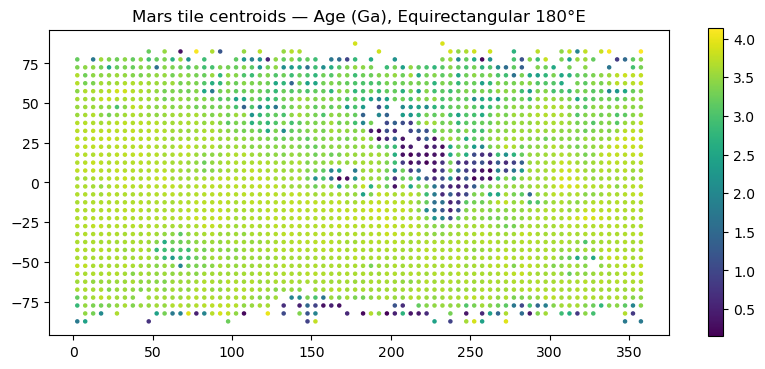

In [11]:
ax = gdf.plot(column="Age", legend=True, figsize=(10,4), markersize=5, cmap="viridis")
ax.set_title("Mars tile centroids — Age (Ga), Equirectangular 180°E")

In [12]:
gdf.head()

,Name,Area,Binning,d_min,d_max,Method,Resurf,N,N_event,Age,...,a0-,a0+,N(1),N(1)-,N(1)+,Source,centroid_lat,centroid_lon,tile_id,geometry
0,12.5,53586.0,pseudo-log,1.0,10,c-fit,1,152.0,152,3.63,...,-2.383,-2.317,0.00448,0.00414,0.00482,tiles_scc/tile_lat-052.50_lon+0012.50.scc,-52.5,12.5,lat-052.50_lon+0012.00,POINT (12.5 -52.5)
1,197.5,80479.0,pseudo-log,1.0,10,c-fit,1,665.0,665,3.81,...,-1.973,-1.940,0.01110,0.01070,0.01150,tiles_scc/tile_lat-022.50_lon+0197.50.scc,-22.5,197.5,lat-022.50_lon+0197.00,POINT (197.5 -22.5)
2,142.5,86124.0,pseudo-log,1.0,10,c-fit,1,259.0,259,3.58,...,-2.471,-2.419,0.00359,0.00338,0.00381,tiles_scc/tile_lat+007.50_lon+0142.50.scc,7.5,142.5,lat+007.50_lon+0142.00,POINT (142.5 7.5)
3,122.5,40784.0,pseudo-log,1.0,10,c-fit,1,54.0,54,3.26,...,-2.804,-2.689,0.00181,0.00157,0.00205,tiles_scc/tile_lat+062.50_lon+0122.50.scc,62.5,122.5,lat+062.50_lon+0122.00,POINT (122.5 62.5)
4,72.5,69444.0,pseudo-log,1.0,10,c-fit,1,81.0,81,3.37,...,-2.725,-2.633,0.00211,0.00188,0.00233,tiles_scc/tile_lat-037.50_lon+0072.50.scc,-37.5,72.5,lat-037.50_lon+0072.00,POINT (72.5 -37.5)


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


NameError: name 'plt' is not defined

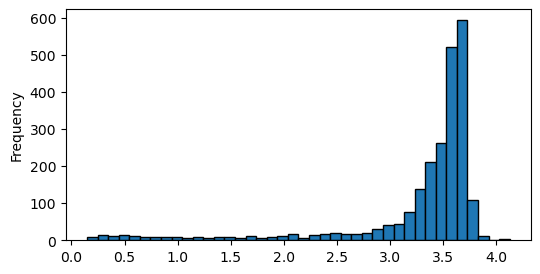

In [13]:
gdf["Age"].plot.hist(bins=40, figsize=(6,3), edgecolor="k")
plt.xlabel("Age (Ga)"); plt.ylabel("Count"); plt.title("Distribution of tile ages")
plt.show()